# Loading Data and Data Processing

There are different types of data that need to be loaded and processed.
1. Texts
  * CSV files
  * Human readable textual files
2. Images
3. Audio

Data may come from different sources:
1. Locally available data
2. URL of dataset
3. Available datasets from Tensorflow and Kaggle
4. Numpy and Pandas arrays

## Texts

### CSV files

#### Loading CSV files

In the following exercise, we see how data is obtained from a CSV file whose URL is known to us and loaded to Tensorflow


In the first approach, we will directly load the data from the URL.

In [2]:
import pandas as pd  # importing the pandas library

csv_data = pd.read_csv(
    "https://storage.googleapis.com/download.tensorflow.org/data/abalone_train.csv",
    names=[
        "Length",
        "Diameter",
        "Height",
        "Whole weight",
        "Shucked weight",
        "Viscera weight",
        "Shell weight",
        "Age",
    ],
)

Print the values of the data frame

In [3]:
csv_data

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
0,0.435,0.335,0.110,0.3340,0.1355,0.0775,0.0965,7
1,0.585,0.450,0.125,0.8740,0.3545,0.2075,0.2250,6
2,0.655,0.510,0.160,1.0920,0.3960,0.2825,0.3700,14
3,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.2600,16
4,0.545,0.420,0.130,0.8790,0.3740,0.1695,0.2300,13
...,...,...,...,...,...,...,...,...
3315,0.605,0.475,0.180,0.9365,0.3940,0.2190,0.2950,15
3316,0.700,0.525,0.190,1.6015,0.7070,0.3650,0.4300,10
3317,0.530,0.420,0.130,0.8365,0.3745,0.1670,0.2490,11
3318,0.395,0.315,0.105,0.3515,0.1185,0.0910,0.1195,16


In the second approach, we will download the data to our disk and create a Pandas dataframe.

In [4]:
from tensorflow.keras import utils  # We use utils for downloading the data

url = "https://storage.googleapis.com/download.tensorflow.org/data/abalone_train.csv"

dataset_dir = utils.get_file(origin=url, cache_dir="./")

I0000 00:00:1791874313.089606   83492 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1791874313.918502   83492 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1791874316.754116   83492 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


145915/145915 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Verify whether the file is downloaded. If the above download is complete, the data will be downloaded to the **datasets** directory in the current folder.

In [5]:
from os import listdir

files = list(listdir("./datasets"))
print(files)

['abalone_train.csv']


In [6]:
csv_data = pd.read_csv(
    "./datasets/abalone_train.csv",
    names=[
        "Length",
        "Diameter",
        "Height",
        "Whole weight",
        "Shucked weight",
        "Viscera weight",
        "Shell weight",
        "Age",
    ],
)

csv_data

,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Age
0,0.435,0.335,0.110,0.3340,0.1355,0.0775,0.0965,7
1,0.585,0.450,0.125,0.8740,0.3545,0.2075,0.2250,6
2,0.655,0.510,0.160,1.0920,0.3960,0.2825,0.3700,14
3,0.545,0.425,0.125,0.7680,0.2940,0.1495,0.2600,16
4,0.545,0.420,0.130,0.8790,0.3740,0.1695,0.2300,13
...,...,...,...,...,...,...,...,...
3315,0.605,0.475,0.180,0.9365,0.3940,0.2190,0.2950,15
3316,0.700,0.525,0.190,1.6015,0.7070,0.3650,0.4300,10
3317,0.530,0.420,0.130,0.8365,0.3745,0.1670,0.2490,11
3318,0.395,0.315,0.105,0.3515,0.1185,0.0910,0.1195,16


#### Preprocessing CSV files

Suppose that our goal is to predict the age from the other features. 

We will first see the unique values of Age.

In [10]:
print(csv_data["Age"].unique())

[ 7  6 14 16 13 10  8  9 12 11 18 15  5 20 17  3  4 19 22 21 23 27 25  1
 24  2]


Now we will create separate dataframe for features.

In [11]:
features = csv_data.copy()
labels = features.pop("Age")

In [ ]:
features

In [ ]:
labels

We see only numerical values in the features. We will now create a numpy array of these features.

In [12]:
import numpy as np

np_features = np.array(features)

print(np_features)

[[0.435  0.335  0.11   ... 0.1355 0.0775 0.0965]
 [0.585  0.45   0.125  ... 0.3545 0.2075 0.225 ]
 [0.655  0.51   0.16   ... 0.396  0.2825 0.37  ]
 ...
 [0.53   0.42   0.13   ... 0.3745 0.167  0.249 ]
 [0.395  0.315  0.105  ... 0.1185 0.091  0.1195]
 [0.45   0.355  0.12   ... 0.1145 0.0665 0.16  ]]


**Note** It is a good practice to normalize the data before training a tensorflow model.

We will use `Normalization` from `tensorflow` for this purpose. 
Note that the function `adopt` should be run only on the test data

In [13]:
from tensorflow.keras import layers

normalize = layers.Normalization()


normalize.adapt(np_features)

E0000 00:00:1791874452.061155   83492 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


#### Using the data for training

Now we are ready to progress with the training.
We have the features and the labels ready.

In [14]:
### Building a model
import tensorflow as tf

model = tf.keras.Sequential(
    [
        normalize,  ## Note the use of Normalization layer
        layers.Dense(64),
        layers.Dense(1),
    ]
)

model.compile(loss=tf.losses.MeanSquaredError(), optimizer=tf.optimizers.Adam())

In [15]:
## Starting the training

history = model.fit(np_features, labels, epochs=10)

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 92.5956
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 51.8821
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 14.7837
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.5937
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 5.0513
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.9676
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.9591
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.9256
Epoch 9/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.9476
Epoch 10/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 4.9182


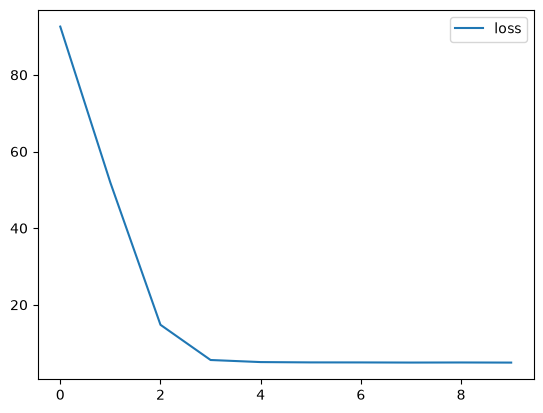

In [17]:
import matplotlib.pyplot as plt

metrics = history.history
plt.plot(history.epoch, metrics["loss"])
plt.legend(["loss"])
plt.show()

In [ ]:
## Printing the model summary
model.summary()

### Text files

Now we will focus on the text files.

We will use Stack Overflow dataset for this part.Note that this is a zipped .tar dataset.


In [18]:
## Download, unzip and untar the dataset

url = "https://storage.googleapis.com/download.tensorflow.org/data/stack_overflow_16k.tar.gz"

dataset_dir = utils.get_file(
    origin=url, untar=True, cache_dir="./datasets", cache_subdir=""
)

6053168/6053168 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


We will now see the contents of the downloaded file(s).

In [19]:
from os import listdir

files = list(listdir("./datasets"))
print(files)

['stack_overflow_16k.tar.gz', 'abalone_train.csv', 'stack_overflow_16k.tar.gz_archive']


If the download is correctly done, we can see the `train` and `test` folders.

In [23]:
files = list(listdir("./datasets/train"))
print(files)

['python', 'csharp', 'javascript', 'java']


In [24]:
files = list(listdir("./datasets/train/javascript"))
print(files[:5])  # print the name of first five files

['1393.txt', '1335.txt', '1478.txt', '180.txt', '1819.txt']


In [25]:
files = list(listdir("./datasets/test"))
print(files)

['python', 'csharp', 'javascript', 'java']


As we can see there are only two folders: `train` and `test`. It is a good practice to create datasets for training, validation and testing.

In the following code, we load the training data from the `train` folder and use 20% of the data for validation.

So far, we have loaded the complete data for training. We will now create batches of size 32.

In [26]:
batch_size = 32
validation_size_percentage = 0.2  # To ensure 80:20 training:validation
seed = 40  # To ensure proper shuffiling

train_batch = utils.text_dataset_from_directory(
    "./datasets/train",
    batch_size=batch_size,
    validation_split=validation_size_percentage,
    subset="training",
    seed=seed,
)

Found 8000 files belonging to 4 classes.
Using 6400 files for training.


We will now see the details of data: text and the associated label using the first batch.

In [27]:
for text_batch, label_batch in train_batch.take(
    1
):  # Taking into consideration the first batch
    for i in range(batch_size):
        print(f"Label: {label_batch[i].numpy()} for the text: {text_batch[i].numpy()}")

Label: 0 for the text: b"looking for file copy function in blank i'm writing a tool that performs copying from usb devices to the local hd - i wonder if there is a function in blank to copy a file from one path to another?\n"
Label: 1 for the text: b'"truncating a blank stack i have a stack&lt;string&gt; defined in blank that i use for navigation through a workflow. ..what i would like to do is ensure that all values in the stack are unique: when a transition to a ""previous"" state occurs, i want to remove everything off the stack after the first occurrence of the previous state in the stack...is there an easy way to do this?..edit: more information was requested. here\'s an example of the contents of a stack:..[state2, state3, state2, state1, startstate]...i need the ability to accept a string, check the stack and see if there are multiple occurrences of it, then pop elements until the ""bottommost"" occurrence of that string. ""truncate"" was probably a bad description of what i wan

But, you may have observed that the labels are not 
'csharp', 'python', 'java', 'javascript', but rather some numbers 0,1, 2, 3.

Now, we will display the associated class names.

In [28]:
for i, label in enumerate(train_batch.class_names):
    print("Label", i, "corresponds to", label)

Label 0 corresponds to csharp
Label 1 corresponds to java
Label 2 corresponds to javascript
Label 3 corresponds to python


Now, we will create the validation dataset. 

Recall that we used the value 'training' for the parameter subset. This time we will use the value 'validation'.

In [29]:
validation_batch = utils.text_dataset_from_directory(
    "./datasets/train",
    batch_size=batch_size,
    validation_split=validation_size_percentage,
    subset="validation",
    seed=seed,
)

Found 8000 files belonging to 4 classes.
Using 1600 files for validation.


And finally, we will create the test batch.

In [30]:
test_batch = utils.text_dataset_from_directory("./datasets/test", batch_size=batch_size)

Found 8000 files belonging to 4 classes.


However, these datasets cannot be yet used for training, since we need vectors for working with Tensorflow. 

Our next goal is to convert the text data to associated vectors.

We will use two approaches:
1. Binary Vectorization (one-hot encoding)
2. 'int' Vectorization (integer indices for each token)

We will first start with **binary Vectorization**

In [31]:
from tensorflow.keras.layers import TextVectorization

vocabulary_size = 10000

binary_vectorize_layer = TextVectorization(
    max_tokens=vocabulary_size, output_mode="binary"
)

In [32]:
train_text = train_batch.map(lambda text, labels: text)
binary_vectorize_layer.adapt(train_text)

In [33]:
for text_batch, label_batch in train_batch.take(1):
    for i in range(1):
        print("Text", text_batch[0].numpy())
        print("Label", label_batch[0].numpy())
        print("Binary Vectorization:")
        print(binary_vectorize_layer(text_batch[0]))  # One-hot encoding

Text b'"add elements to arraylist<arraylist<string>> i have an arraylist of arraylist. how can i add an element to the list in specific position? ..example: ..arraylist&lt;arraylist&lt;string&gt;&gt;=new arraylist&lt;&gt;(list,list2,.....,listn);...i want to add an element to list2 for example."\n'
Label 1
Binary Vectorization:
tf.Tensor([1 1 1 ... 0 0 0], shape=(10000,), dtype=int64)


The above output corresponds to one-hot encoding value of the text.

We will first start with **'int' Vectorization**

Unlike 'Binary' Vectorization, we also need the maximum sequence length.

Long texts will be truncated to this maximum length.

In [34]:
from tensorflow.keras.layers import TextVectorization

vocabulary_size = 10000
max_sequence_length = 200

int_vectorize_layer = TextVectorization(
    max_tokens=vocabulary_size,
    output_sequence_length=max_sequence_length,
    output_mode="int",
)

In [35]:
train_text = train_batch.map(lambda text, labels: text)
int_vectorize_layer.adapt(train_text)

In [36]:
for text_batch, label_batch in train_batch.take(1):
    for i in range(1):
        print("Text", text_batch[0].numpy())
        print("Label", label_batch[0].numpy())
        print("Binary Vectorization:")
        print(int_vectorize_layer(text_batch[0]))  # Check the length of the sequence

Text b'"i am learning blank i want to put in a int but cant figure how to convert it i want the user to be able to enter the number at the menu however when i do this it says its a string being enter. i have tried to convert as i left the code in but it will not work...namespace day1.day1.exercises.{.    class passwordgenerator.    {.        static void main(string[] args).        {.            int mainmenu = 0;..            console.foregroundcolor = consolecolor.green;.            console.writeline(""----------------------------------------------------------------"");.            console.writeline(""                        password generator"");.            console.writeline(""----------------------------------------------------------------"");..            console.writeline(""1 - generate password"");.            console.writeline(""2 - help"");.            console.writeline(""3 - exit"");..            mainmenu = console.readline();..            int input = convert.toint16(mainmenu);

To understand what the above sequence signify, we will look up in the vocabulary.

In [37]:
for i in int_vectorize_layer(text_batch[0]):
    print(f"{i}: ", int_vectorize_layer.get_vocabulary()[i])

3:  i
34:  am
706:  learning
16:  blank
3:  i
43:  want
4:  to
307:  put
7:  in
5:  a
27:  int
28:  but
166:  cant
390:  figure
25:  how
4:  to
215:  convert
11:  it
3:  i
43:  want
2:  the
107:  user
4:  to
33:  be
239:  able
4:  to
190:  enter
2:  the
66:  number
61:  at
2:  the
665:  menu
252:  however
46:  when
3:  i
39:  do
13:  this
11:  it
600:  says
95:  its
5:  a
18:  string
285:  being
190:  enter
3:  i
17:  have
148:  tried
4:  to
215:  convert
36:  as
3:  i
392:  left
2:  the
30:  code
7:  in
28:  but
11:  it
72:  will
21:  not
1:  [UNK]
1:  [UNK]
29:  class
1:  [UNK]
52:  static
42:  void
167:  mainstring
154:  args
27:  int
9674:  mainmenu
19:  0
3517:  consoleforegroundcolor
8209:  consolecolorgreen
905:  consolewriteline
905:  consolewriteline
430:  password
1833:  generator
905:  consolewriteline
1:  [UNK]
701:  generate
430:  password
1:  [UNK]
104:  help
1:  [UNK]
688:  exit
9674:  mainmenu
587:  consolereadline
27:  int
90:  input
1:  [UNK]
10:  if
90:  input
26:  1

Now, we create functions to apply binary or 'int' vectorization to the dataset.

In [38]:
def binary_vectorize(text, label):
    text = tf.expand_dims(text, -1)
    return binary_vectorize_layer(text), label

In [39]:
def int_vectorize(text, label):
    text = tf.expand_dims(text, -1)
    return int_vectorize_layer(text), label

In [40]:
binary_train_batch = train_batch.map(binary_vectorize)
binary_validation_batch = validation_batch.map(binary_vectorize)
binary_test_batch = test_batch.map(binary_vectorize)

In [41]:
int_train_batch = train_batch.map(int_vectorize)
int_validation_batch = validation_batch.map(int_vectorize)
int_test_batch = test_batch.map(int_vectorize)

In [42]:
# Training using binary 'Vectors'
from tensorflow.keras import losses

num_labels = 4
binary_model = tf.keras.Sequential([layers.Dense(num_labels)])

binary_model.compile(
    loss=losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer="adam",
    metrics=["accuracy"],
)

history = binary_model.fit(
    binary_train_batch, validation_data=binary_validation_batch, epochs=10
)

Epoch 1/10


/home/thomas/Bureau/CPE/S9/IA Machine Learning/ia_deep_learning_projet/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.6455 - loss: 1.1199 - val_accuracy: 0.7619 - val_loss: 0.9304
Epoch 2/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8206 - loss: 0.7786 - val_accuracy: 0.7931 - val_loss: 0.7665
Epoch 3/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8656 - loss: 0.6262 - val_accuracy: 0.8031 - val_loss: 0.6809
Epoch 4/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8906 - loss: 0.5324 - val_accuracy: 0.8037 - val_loss: 0.6293
Epoch 5/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9077 - loss: 0.4660 - val_accuracy: 0.8081 - val_loss: 0.5933
Epoch 6/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9206 - loss: 0.4157 - val_accuracy: 0.8094 - val_loss: 0.5680
Epoch 7/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9303 - loss: 0.3755 - val_accuracy: 0.8125 - val_loss: 0.5494
Epoch 8/10
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9370 - loss: 0.3425 - val_accuracy: 0.8138 - val

In [43]:
print(binary_model.summary())

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 4)              │        40,004 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,014 (468.81 KB)

 Trainable params: 40,004 (156.27 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 80,010 (312.54 KB)

None


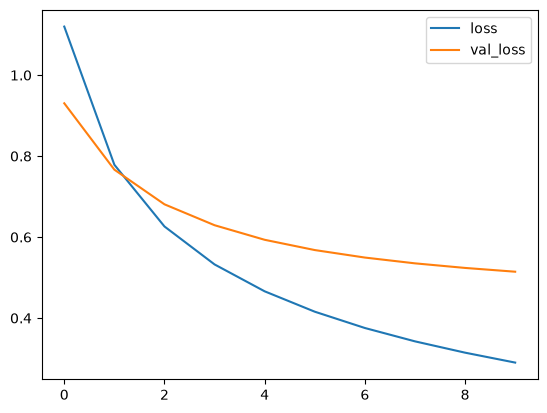

In [44]:
metrics = history.history
plt.plot(history.epoch, metrics["loss"], metrics["val_loss"])
plt.legend(["loss", "val_loss"])
plt.show()

In [45]:
num_labels = 4
vocab_size = vocabulary_size + 1

int_model = tf.keras.Sequential(
    [
        layers.Embedding(vocab_size, 64, mask_zero=True),
        layers.Conv1D(64, 5, padding="valid", activation="relu", strides=2),
        layers.GlobalMaxPooling1D(),
        layers.Dense(num_labels),
    ]
)

int_model.compile(
    loss=losses.SparseCategoricalCrossentropy(from_logits=True),
    optimizer="adam",
    metrics=["accuracy"],
)
history = int_model.fit(int_train_batch, validation_data=int_validation_batch, epochs=5)

Epoch 1/5


/home/thomas/Bureau/CPE/S9/IA Machine Learning/ia_deep_learning_projet/venv/lib/python3.12/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'conv1d' (of type Conv1D) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


200/200 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.5175 - loss: 1.1064 - val_accuracy: 0.6819 - val_loss: 0.7734
Epoch 2/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.7603 - loss: 0.6226 - val_accuracy: 0.7812 - val_loss: 0.5778
Epoch 3/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - accuracy: 0.8714 - loss: 0.3905 - val_accuracy: 0.7862 - val_loss: 0.5281
Epoch 4/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.9455 - loss: 0.2193 - val_accuracy: 0.7931 - val_loss: 0.5268
Epoch 5/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.9786 - loss: 0.1125 - val_accuracy: 0.7969 - val_loss: 0.5611


In [46]:
print(int_model.summary())

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 98, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 64)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,982,606 (7.56 MB)

 Trainable params: 660,868 (2.52 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,321,738 (5.04 MB)

None


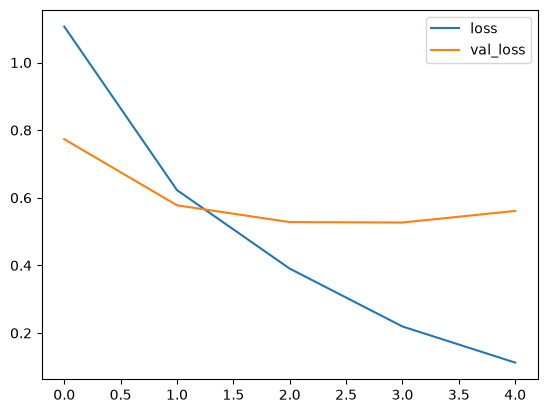

In [47]:
metrics = history.history
plt.plot(history.epoch, metrics["loss"], metrics["val_loss"])
plt.legend(["loss", "val_loss"])
plt.show()

In [48]:
binary_loss, binary_accuracy = binary_model.evaluate(binary_test_batch)
int_loss, int_accuracy = int_model.evaluate(int_test_batch)

print("Binary model accuracy: {:2.2%}".format(binary_accuracy))
print("Int model accuracy: {:2.2%}".format(int_accuracy))

250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8156 - loss: 0.5160
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8046 - loss: 0.5501
Binary model accuracy: 81.56%
Int model accuracy: 80.46%


## Images

### Loading Image dataset

In [49]:
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = tf.keras.utils.get_file(
    origin=url, cache_dir="./datasets", cache_subdir="", untar=True
)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 10s 0us/step


We will now check the contents of the downloded data

In [50]:
from os import listdir

files = list(listdir("./datasets"))
print(files)

['flower_photos.tgz_archive', 'flower_photos.tgz', 'test', 'abalone_train.csv', 'README.md', 'train']


In [52]:
files = list(listdir("./datasets/flower_photos"))
print(files)

['tulips', 'dandelion', 'roses', 'sunflowers', 'LICENSE.txt', 'daisy']


#### Image data processing for building Tensorflow models

For the processing of images, we need the values of batch size and image size (height and weight).

In [53]:
batch_size = 32
img_height = 180
img_width = 180

For preparing the batch, we make use of `image_dataset_from_directory`. Note the parameter `image_size`. 

We will first create the training batch.

In [54]:
batch_size = 32
validation_size_percentage = 0.2  # To ensure 80:20 training:validation
seed = 40  # To ensure proper shuffiling

train_batch = utils.image_dataset_from_directory(
    "./datasets/flower_photos",
    batch_size=batch_size,
    validation_split=validation_size_percentage,
    subset="training",
    image_size=(img_height, img_width),
    seed=seed,
)

Found 3670 files belonging to 5 classes.
Using 2936 files for training.


Next, we will first create the validation batch.

In [55]:
validation_batch = utils.image_dataset_from_directory(
    "./datasets/flower_photos",
    batch_size=batch_size,
    validation_split=validation_size_percentage,
    subset="validation",
    image_size=(img_height, img_width),
    seed=seed,
)

Found 3670 files belonging to 5 classes.
Using 734 files for validation.


Let's see how the class names have been identified by Tensorflow.

In [56]:
class_names = train_batch.class_names
print(class_names)

['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


Next, we will plot the images as well as their labels.

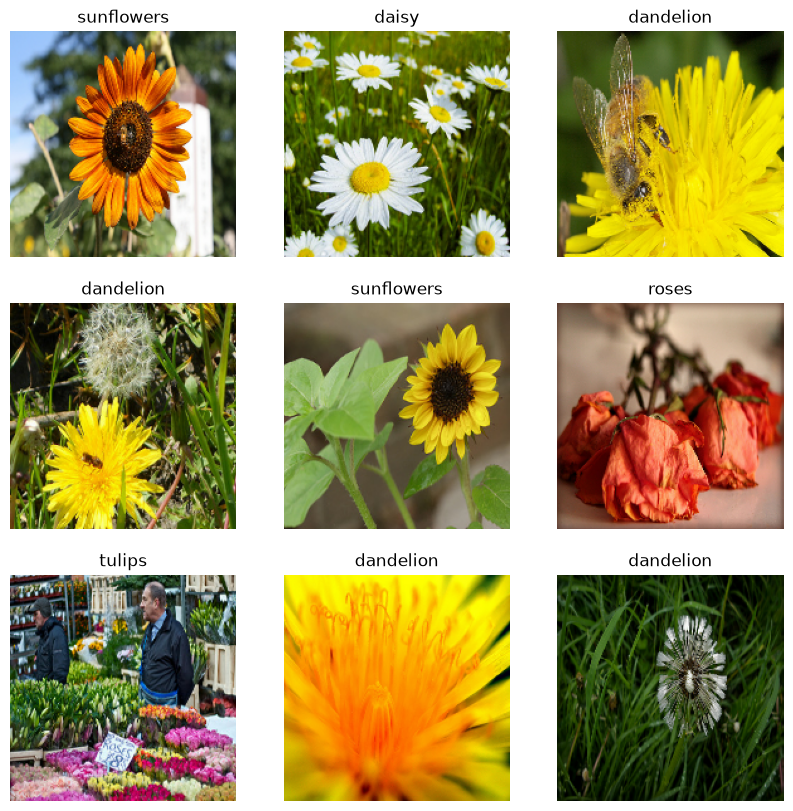

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_batch.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

We will now see the details of the first image from a batch: the shape of the image as well as the shape of the labels.

In [58]:
for images, labels in train_batch.take(1):
    print(images[0].shape)
    print(labels.shape)
    break

(180, 180, 3)
(32,)


As we have seen before, it is very important to normalize the images.

In [59]:
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

We now create the normalized batch.

In [60]:
normalized_batch = train_batch.map(lambda x, y: (normalization_layer(x), y))

Let's now see some information from an image of a normalized batch.

In [61]:
for images, labels in normalized_batch.take(1):
    print(np.min(images[0]), np.max(images[0]))

0.0 1.0


We will now build a Tensorflow model for the image classification.

We add a normalization later in this model.

In [62]:
num_classes = 5

model = tf.keras.Sequential(
    [
        tf.keras.layers.Rescaling(1.0 / 255),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(num_classes),
    ]
)

model.compile(
    optimizer="adam",
    loss=tf.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

We now perform the training of the model.

In [63]:
history = model.fit(train_batch, validation_data=validation_batch, epochs=3)

Epoch 1/3


W0000 00:00:1791876148.309429   83658 cpu_allocator_impl.cc:82] Allocation of 129777664 exceeds 10% of free system memory.
W0000 00:00:1791876148.981100   83659 cpu_allocator_impl.cc:82] Allocation of 64888832 exceeds 10% of free system memory.
W0000 00:00:1791876148.981227   83659 cpu_allocator_impl.cc:82] Allocation of 129777664 exceeds 10% of free system memory.


 1/92 ━━━━━━━━━━━━━━━━━━━━ 5:55 4s/step - accuracy: 0.1250 - loss: 1.6107

W0000 00:00:1791876149.488604   83659 cpu_allocator_impl.cc:82] Allocation of 129777664 exceeds 10% of free system memory.
W0000 00:00:1791876150.052041   83659 cpu_allocator_impl.cc:82] Allocation of 64888832 exceeds 10% of free system memory.


92/92 ━━━━━━━━━━━━━━━━━━━━ 79s 822ms/step - accuracy: 0.4401 - loss: 1.3241 - val_accuracy: 0.5027 - val_loss: 1.1695
Epoch 2/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 73s 797ms/step - accuracy: 0.5981 - loss: 1.0059 - val_accuracy: 0.5804 - val_loss: 1.0325
Epoch 3/3
92/92 ━━━━━━━━━━━━━━━━━━━━ 109s 1s/step - accuracy: 0.6723 - loss: 0.8838 - val_accuracy: 0.5872 - val_loss: 0.9889


In [64]:
print(model.summary())

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 87, 87, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 43, 43, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 41, 41, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,975,697 (18.98 MB)

 Trainable params: 1,658,565 (6.33 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,317,132 (12.65 MB)

None


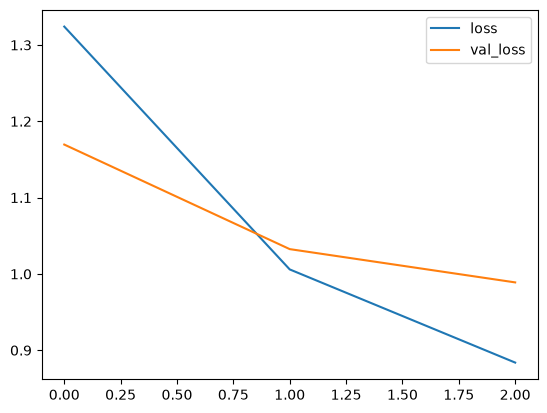

In [65]:
metrics = history.history
plt.plot(history.epoch, metrics["loss"], metrics["val_loss"])
plt.legend(["loss", "val_loss"])
plt.show()

## Audio

### Loading Audio data

In [66]:
url = "http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip"
data_dir = tf.keras.utils.get_file(
    origin=url, cache_dir="./datasets", cache_subdir="", extract=True
)

182082353/182082353 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


In [68]:
from os import listdir

files = list(listdir("./datasets"))
print(files)

['mini_speech_commands', 'flower_photos', 'test', 'abalone_train.csv', 'README.md', 'train']


In [69]:
files = list(listdir("./datasets/mini_speech_commands"))
commands = []
for c in files:
    if c != "README.md":
        commands.append(c)
print(commands)

['no', 'up', 'go', 'yes', 'right', 'stop', 'down', 'left']


In [70]:
from glob import glob

filenames = glob("./datasets/mini_speech_commands/*/*")
filenames = tf.random.shuffle(filenames)
print(f"Number of examples: {len(filenames)}")

Number of examples: 8000


In [71]:
train_files = filenames[:6400]
val_files = filenames[6400 : 6400 + 800]
test_files = filenames[-800:]

In [72]:
test_file = tf.io.read_file(train_files[0])
test_audio, _ = tf.audio.decode_wav(contents=test_file)
test_audio.shape

TensorShape([16000, 1])

In [73]:
def decode_audio(audio_binary):
    audio, _ = tf.audio.decode_wav(contents=audio_binary)
    return tf.squeeze(audio, axis=-1)

In [74]:
import os


def get_label_from_filepath(file_path):

    parts = tf.strings.split(input=file_path, sep=os.path.sep)
    print(parts[-2])
    return parts[-2]

In [75]:
t = get_label_from_filepath(train_files[0])
print(type(t))
print(t.numpy())

tf.Tensor(b'down', shape=(), dtype=string)
<class 'tensorflow.python.framework.ops.EagerTensor'>
b'down'


In [76]:
def get_waveform_and_label(file_path):
    print(t.numpy())
    label = get_label_from_filepath(file_path)
    audio_binary = tf.io.read_file(file_path)
    waveform = decode_audio(audio_binary)
    return waveform, label

In [77]:
AUTOTUNE = tf.data.AUTOTUNE

files_ds = tf.data.Dataset.from_tensor_slices(train_files)

waveform_ds = files_ds.map(map_func=get_waveform_and_label, num_parallel_calls=AUTOTUNE)

b'down'
Tensor("strided_slice:0", shape=(), dtype=string)


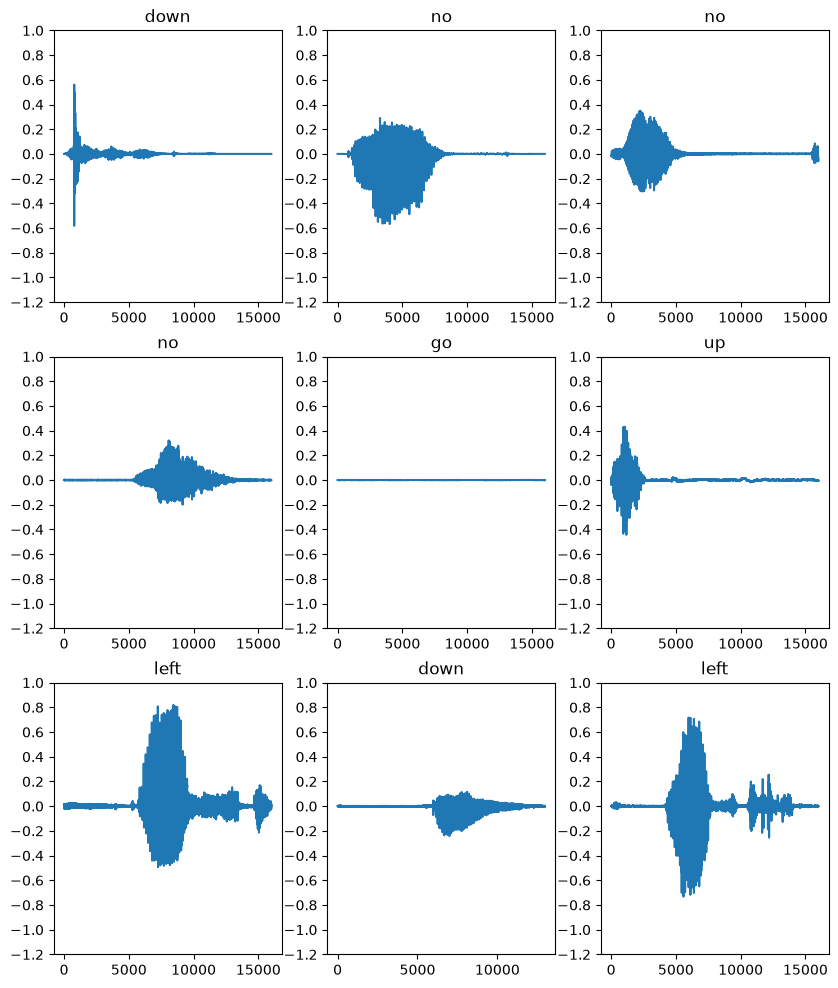

In [78]:
import matplotlib.pyplot as plt
import numpy as np

rows = 3
cols = 3
n = rows * cols
fig, axes = plt.subplots(rows, cols, figsize=(10, 12))

for i, (audio, label) in enumerate(waveform_ds.take(n)):
    r = i // cols
    c = i % cols
    ax = axes[r][c]
    ax.plot(audio.numpy())
    ax.set_yticks(np.arange(-1.2, 1.2, 0.2))
    label = label.numpy().decode("utf-8")
    ax.set_title(label)

plt.show()

In [79]:
def get_spectrogram(waveform):
    # Zero-padding for an audio waveform with less than 16,000 samples.
    input_len = 16000
    waveform = waveform[:input_len]
    zero_padding = tf.zeros([16000] - tf.shape(waveform), dtype=tf.float32)
    # Cast the waveform tensors' dtype to float32.
    waveform = tf.cast(waveform, dtype=tf.float32)
    # Concatenate the waveform with `zero_padding`, which ensures all audio
    # clips are of the same length.
    equal_length = tf.concat([waveform, zero_padding], 0)
    # Convert the waveform to a spectrogram via a STFT.
    spectrogram = tf.signal.stft(equal_length, frame_length=255, frame_step=128)
    # Obtain the magnitude of the STFT.
    spectrogram = tf.abs(spectrogram)
    # Add a `channels` dimension, so that the spectrogram can be used
    # as image-like input data with convolution layers (which expect
    # shape (`batch_size`, `height`, `width`, `channels`).
    spectrogram = spectrogram[..., tf.newaxis]
    return spectrogram

In [80]:
from IPython import display

for waveform, label in waveform_ds.take(1):
    label = label.numpy().decode("utf-8")
    spectrogram = get_spectrogram(waveform)

print("Label:", label)
print("Waveform shape:", waveform.shape)
print("Spectrogram shape:", spectrogram.shape)
print("Audio playback")
display.display(display.Audio(waveform, rate=16000))

Label: down
Waveform shape: (16000,)
Spectrogram shape: (124, 129, 1)
Audio playback


In [81]:
def plot_spectrogram(spectrogram, ax):
    if len(spectrogram.shape) > 2:
        assert len(spectrogram.shape) == 3
        spectrogram = np.squeeze(spectrogram, axis=-1)
    # Convert the frequencies to log scale and transpose, so that the time is
    # represented on the x-axis (columns).
    # Add an epsilon to avoid taking a log of zero.
    log_spec = np.log(spectrogram.T + np.finfo(float).eps)
    height = log_spec.shape[0]
    width = log_spec.shape[1]
    X = np.linspace(0, np.size(spectrogram), num=width, dtype=int)
    Y = range(height)
    ax.pcolormesh(X, Y, log_spec, shading="auto")

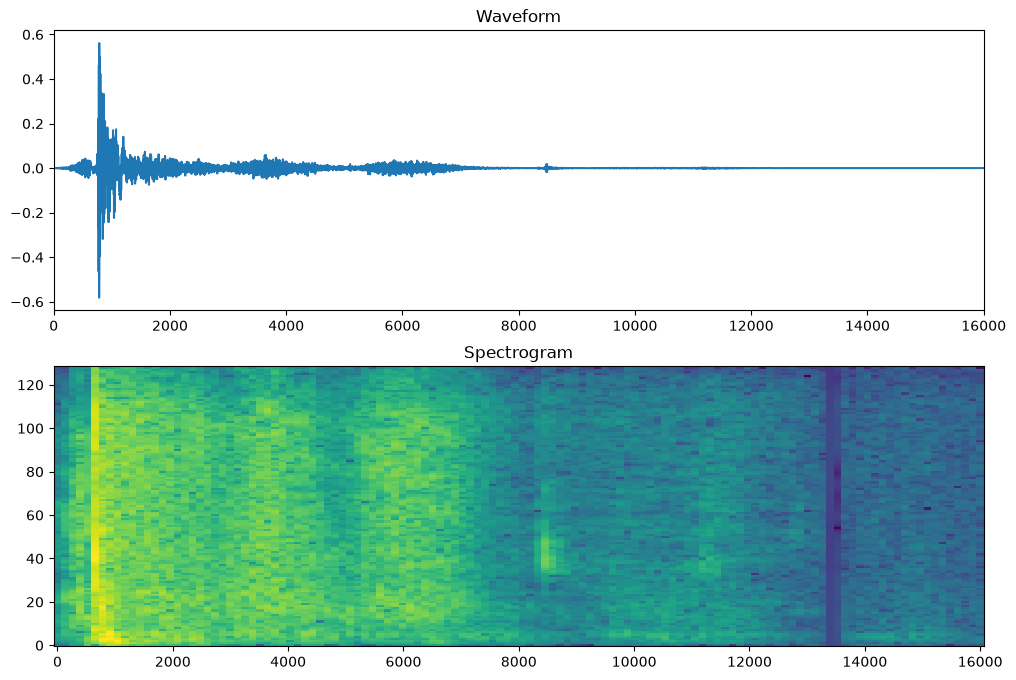

In [82]:
fig, axes = plt.subplots(2, figsize=(12, 8))
timescale = np.arange(waveform.shape[0])
axes[0].plot(timescale, waveform.numpy())
axes[0].set_title("Waveform")
axes[0].set_xlim([0, 16000])

plot_spectrogram(spectrogram.numpy(), axes[1])
axes[1].set_title("Spectrogram")
plt.show()

In [83]:
def get_spectrogram_and_label_id(audio, label):
    spectrogram = get_spectrogram(audio)
    label_id = tf.argmax(label == commands)
    return spectrogram, label_id

In [84]:
spectrogram_ds = waveform_ds.map(
    map_func=get_spectrogram_and_label_id, num_parallel_calls=AUTOTUNE
)

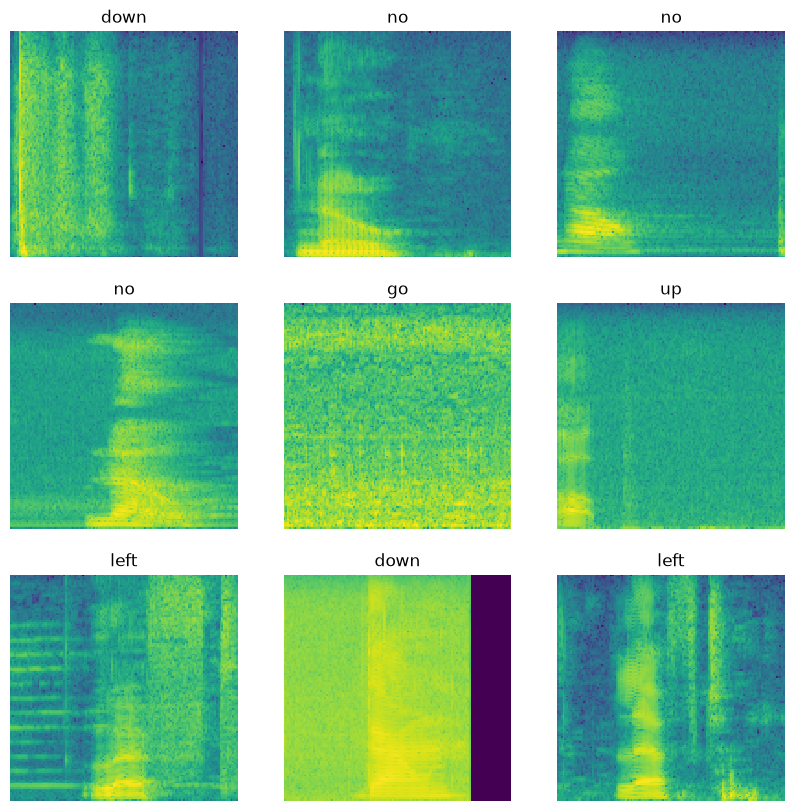

In [85]:
rows = 3
cols = 3
n = rows * cols
fig, axes = plt.subplots(rows, cols, figsize=(10, 10))

for i, (spectrogram, label_id) in enumerate(spectrogram_ds.take(n)):
    r = i // cols
    c = i % cols
    ax = axes[r][c]
    plot_spectrogram(spectrogram.numpy(), ax)
    ax.set_title(commands[label_id.numpy()])
    ax.axis("off")

plt.show()

In [86]:
def preprocess_dataset(files):
    files_ds = tf.data.Dataset.from_tensor_slices(files)
    output_ds = files_ds.map(
        map_func=get_waveform_and_label, num_parallel_calls=AUTOTUNE
    )
    output_ds = output_ds.map(
        map_func=get_spectrogram_and_label_id, num_parallel_calls=AUTOTUNE
    )
    return output_ds

In [87]:
train_ds = spectrogram_ds
val_ds = preprocess_dataset(val_files)
test_ds = preprocess_dataset(test_files)

b'down'
Tensor("strided_slice:0", shape=(), dtype=string)
b'down'
Tensor("strided_slice:0", shape=(), dtype=string)


In [88]:
batch_size = 64
train_ds = train_ds.batch(batch_size)
val_ds = val_ds.batch(batch_size)

In [89]:
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

In [90]:
for spectrogram, _ in spectrogram_ds.take(1):
    input_shape = spectrogram.shape
print("Input shape:", input_shape)
num_labels = len(commands)

Input shape: (124, 129, 1)


In [91]:
from tensorflow.keras import layers
from tensorflow.keras import models

# Instantiate the `tf.keras.layers.Normalization` layer.
norm_layer = layers.Normalization()
# Fit the state of the layer to the spectrograms
# with `Normalization.adapt`.
norm_layer.adapt(data=spectrogram_ds.map(map_func=lambda spec, label: spec))

model = models.Sequential(
    [
        layers.Input(shape=input_shape),
        # Downsample the input.
        layers.Resizing(32, 32),
        # Normalize.
        norm_layer,
        layers.Conv2D(32, 3, activation="relu"),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(num_labels),
    ]
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_1 (Normalization) │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,611 (6.20 MB)

 Trainable params: 1,625,608 (6.20 MB)

 Non-trainable params: 3 (16.00 B)

In [92]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

In [93]:
EPOCHS = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2),
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 25s 224ms/step - accuracy: 0.3613 - loss: 1.7535 - val_accuracy: 0.5437 - val_loss: 1.3247
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 176ms/step - accuracy: 0.5777 - loss: 1.2124 - val_accuracy: 0.6625 - val_loss: 0.9717
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 183ms/step - accuracy: 0.6684 - loss: 0.9242 - val_accuracy: 0.7387 - val_loss: 0.8009
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 169ms/step - accuracy: 0.7248 - loss: 0.7682 - val_accuracy: 0.7688 - val_loss: 0.6892
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 175ms/step - accuracy: 0.7658 - loss: 0.6550 - val_accuracy: 0.7700 - val_loss: 0.6622
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 17s 171ms/step - accuracy: 0.7927 - loss: 0.5848 - val_accuracy: 0.7875 - val_loss: 0.6125
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 189ms/step - accuracy: 0.8109 - loss: 0.5254 - val_accuracy: 0.8050 - val_loss: 0.5575
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 17s 170ms/step - accuracy: 0.8313 - loss: 0

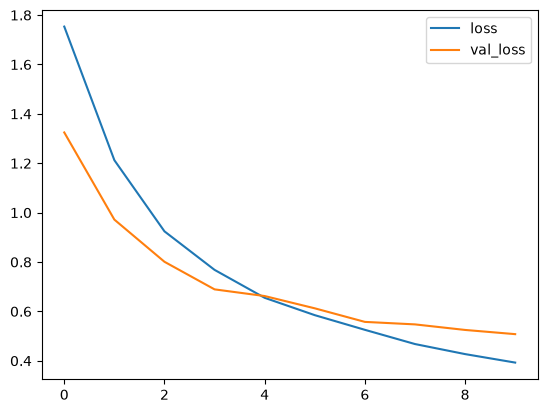

In [94]:
metrics = history.history
plt.plot(history.epoch, metrics["loss"], metrics["val_loss"])
plt.legend(["loss", "val_loss"])
plt.show()

In [95]:
test_audio = []
test_labels = []

for audio, label in test_ds:
    test_audio.append(audio.numpy())
    test_labels.append(label.numpy())

test_audio = np.array(test_audio)
test_labels = np.array(test_labels)

In [96]:
y_pred = np.argmax(model.predict(test_audio), axis=1)
y_true = test_labels

test_acc = sum(y_pred == y_true) / len(y_true)
print(f"Test set accuracy: {test_acc:.0%}")

25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step
Test set accuracy: 84%


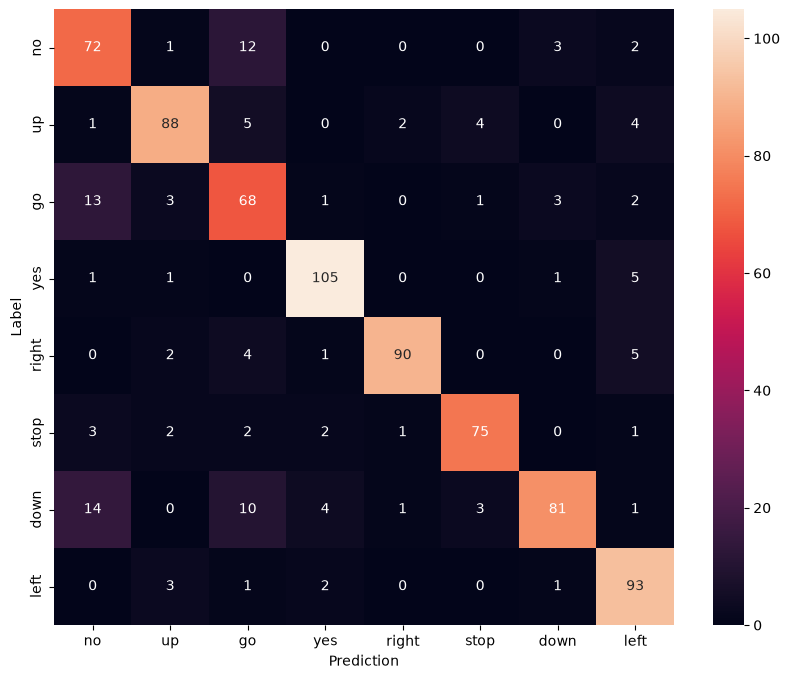

In [98]:
import seaborn as sns

confusion_mtx = tf.math.confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(
    confusion_mtx, xticklabels=commands, yticklabels=commands, annot=True, fmt="g"
)
plt.xlabel("Prediction")
plt.ylabel("Label")
plt.show()

### References
1. [Tensorflow: Load CSV data](https://www.tensorflow.org/tutorials/load_data/csv?hl=en)
2. [Tensorflow: Load text](https://www.tensorflow.org/tutorials/load_data/text?hl=en])
3. [tf.keras.utils.text_dataset_from_directory](https://www.tensorflow.org/api_docs/python/tf/keras/utils/text_dataset_from_directory)
4. [tf.keras.utils.get_file](https://www.tensorflow.org/api_docs/python/tf/keras/utils/get_file)
5. [tf.keras.layers.TextVectorization](https://www.tensorflow.org/api_docs/python/tf/keras/layers/TextVectorization)
6. [Load and preprocess images](https://www.tensorflow.org/tutorials/load_data/images?hl=en%5D)
7. [Simple audio recognition: Recognizing keywords](https://www.tensorflow.org/tutorials/audio/simple_audio)